In [1]:
import pandas as pd
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

In [9]:
alimentacion = pd.read_csv("./dataframes/alimentacion_df_limpio_DEs_catg_etiq.csv", sep=',')

C:\Users\alexa\AppData\Local\Temp\ipykernel_18636\2407166390.py:1: DtypeWarning: Columns (9: categories) have mixed types. Specify dtype option on import or set low_memory=False.
  alimentacion = pd.read_csv("./dataframes/alimentacion_df_limpio_DEs_catg_etiq.csv", sep=',')


In [10]:
alimentacion["marca"] = "marca de fabricante"

In [11]:
alimentacion["brands"].value_counts()

brands
Sin información    123564
BonÀrea             11254
Hacendado            8455
Carrefour            6189
Eroski               2810
                    ...  
Candy Glam              1
Cop's                   1
Misky Toffees           1
yuspe                   1
capayan                 1
Name: count, Length: 40971, dtype: int64

In [12]:
alimentacion.loc[alimentacion["brands"].str.contains("mercadona|hacendado|carrefour|eroski|dia|lidl|aldi", case=False), 'marca'] = "marca blanca"

In [13]:
alimentacion["marca"].value_counts()

marca
marca de fabricante    297974
marca blanca            33191
Name: count, dtype: int64

In [19]:
from scipy.stats import chi2_contingency
# ==========================================
# 2. TEST DE CHI-CUADRADO
# ==========================================
contingency_table = pd.crosstab(alimentacion['marca'], alimentacion['tiene_algun_DE'])
chi2, p_val, dof, expected = chi2_contingency(contingency_table)

print("--- 1. TEST DE CHI-CUADRADO ---")
print(f"Estadístico Chi2: {chi2:.4f}")
print(f"P-valor: {p_val:.4e}")
print("\nTabla de contingencia:")
print(contingency_table)
print("-" * 40)

--- 1. TEST DE CHI-CUADRADO ---
Estadístico Chi2: 1510.1972
P-valor: 0.0000e+00

Tabla de contingencia:
tiene_algun_DE        False  True 
marca                             
marca blanca          31506   1685
marca de fabricante  292558   5416
----------------------------------------


In [16]:
import statsmodels.formula.api as smf

# 1. Creamos una copia o una columna auxiliar numérica para la variable dependiente
alimentacion['tiene_algun_DE_int'] = alimentacion['tiene_algun_DE'].astype(int)

# 2. Ejecutamos el modelo logístico incluyendo el tipo de marca y el grupo NOVA
# Usamos una estructura que cruce marca y nova_group para comprobar la transversalidad
modelo_marca = smf.logit(
    "tiene_algun_DE_int ~ C(marca) + C(nova_group)", 
    data=alimentacion
).fit()

print(modelo_marca.summary())

Optimization terminated successfully.
         Current function value: 0.053258
         Iterations 12
                           Logit Regression Results                           
Dep. Variable:     tiene_algun_DE_int   No. Observations:               331165
Model:                          Logit   Df Residuals:                   331159
Method:                           MLE   Df Model:                            5
Date:               ma., 10 nov. 2026   Pseudo R-squ.:                  0.4859
Time:                        22:50:01   Log-Likelihood:                -17637.
converged:                       True   LL-Null:                       -34309.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept                          -8.0200      0.099    -80.655 

"El incremento del riesgo de disruptores endocrinos es transversal y estructural al ultraprocesamiento (NOVA 4). Aunque existe una ligera diferencia estadística a favor de la marca blanca, la magnitud del riesgo la determina la escala de procesamiento industrial y no el posicionamiento comercial o la enseña del producto."

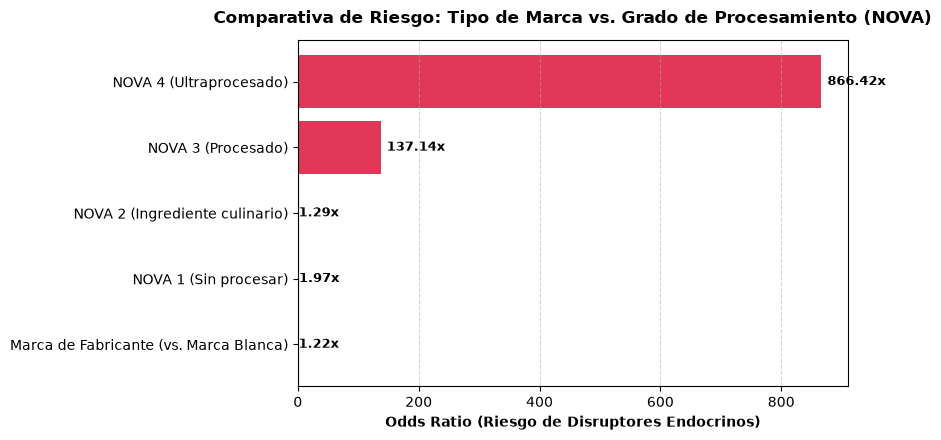

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Calculamos los Odds Ratios del modelo de marcas
params = modelo_marca.params
conf = modelo_marca.conf_int()
conf['OR'] = np.exp(params)

df_marca = pd.DataFrame({
    'Variable': conf.index,
    'OR': conf['OR']
}).drop(index='Intercept')

# Nombres amigables para el público
nombres = {
    'C(marca)[T.marca de fabricante]': 'Marca de Fabricante (vs. Marca Blanca)',
    'C(nova_group)[T.1.0]': 'NOVA 1 (Sin procesar)',
    'C(nova_group)[T.2.0]': 'NOVA 2 (Ingrediente culinario)',
    'C(nova_group)[T.3.0]': 'NOVA 3 (Procesado)',
    'C(nova_group)[T.4.0]': 'NOVA 4 (Ultraprocesado)'
}

df_marca['Variable'] = df_marca['Variable'].map(nombres)
df_marca = df_marca.dropna()

# 2. Representación gráfica
plt.figure(figsize=(9, 4.5))
colores = ['crimson' if 'NOVA 4' in var or 'NOVA 3' in var else 'steelblue' for var in df_marca['Variable']]

bars = plt.barh(df_marca['Variable'], df_marca['OR'], color=colores, alpha=0.85)
plt.axvline(x=1, color='black', linestyle='--', alpha=0.6, label='Línea base (Marca Blanca / Sin riesgo)')

plt.title('Comparativa de Riesgo: Tipo de Marca vs. Grado de Procesamiento (NOVA)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Odds Ratio (Riesgo de Disruptores Endocrinos)', fontsize=10, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Añadir valores exactos sobre las barras
for bar in bars:
    width = bar.get_width()
    plt.text(width + (10 if width > 5 else 0.05), bar.get_y() + bar.get_height()/2, 
             f'{width:.2f}x', va='center', ha='left', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()